In [1]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path.home() / "/mnt/d/DS_Course/11.Career_prep/To_Job/Projects/Data_Analyst/Sales_Dashboard"
DATA_PATH = PROJECT_DIR / "data/processed" / "sales_data_cleaned.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())
display(df.dtypes)

Dataset shape: (9800, 17)


,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code      float64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
dtype: object

In [2]:
df["Postal Code"] = df["Postal Code"].astype(str)
df[["Ship Date", "Order Date"]] = df[["Ship Date", "Order Date"]].apply(pd.to_datetime)
display(df.dtypes)

Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code                 str
Region                      str
Product ID                  str
Category                    str
Sub-Category                str
Product Name                str
Sales                   float64
dtype: object

1. Prepare the data and engineer the features. Predicting sales using product, order, location and time attributes.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(DATA_PATH)

model_df = df.copy()

model_df["Sales"] = pd.to_numeric(
    model_df["Sales"], errors="coerce"
)

model_df["Order Date"] = pd.to_datetime(
    model_df["Order Date"], errors="coerce"
)

model_df = model_df.dropna(
    subset=["Sales", "Order ID", "Order Date"]
)

model_df["Order_Month"] = model_df["Order Date"].dt.month
model_df["Order_DayOfWeek"] = model_df["Order Date"].dt.dayofweek


features = [
    "Category",
    "Sub-Category",
    "Product ID",
    "Region",
    "State",
    "Segment",
    "Ship Mode",
    "Order_Month",
    "Order_DayOfWeek"
]

X = model_df[features].copy()
y = model_df["Sales"].copy()

print("Rows used:", len(model_df))
print("Features:", features)

Rows used: 9800
Features: ['Category', 'Sub-Category', 'Product ID', 'Region', 'State', 'Segment', 'Ship Mode', 'Order_Month', 'Order_DayOfWeek']


2. Split the data by order. Keep records sharing an Order ID together.

In [6]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=model_df["Order ID"])
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

train_orders = set(model_df.iloc[train_idx]["Order ID"])
test_orders = set(model_df.iloc[test_idx]["Order ID"])

print("Orders shared across splits:", len(train_orders & test_orders))

Training rows: 7848
Testing rows: 1952
Orders shared across splits: 0


3. Build a preprocessor pipeline. One-hot encoding, impute missing values, and scale numeric features for consistency.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

categorical_features = [
    "Category",
    "Sub-Category",
    "Product ID",
    "Region",
    "State",
    "Segment",
    "Ship Mode"
]

numeric_features = [
    "Order_Month",
    "Order_DayOfWeek"
]

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=2
    ))
])

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("categorical", categorical_pipeline, categorical_features),
    ("numeric", numeric_pipeline, numeric_features)
    ])

4. Train and compare three models.

- Linear Regression: a simple, interpretable baseline.



- Decision Tree: captures nonlinear relationships and feature interactions.



- Random Forest: combines multiple trees, often improving generalization over a single tree.

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=15,
        min_samples_leaf=5,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    predictions  = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results).sort_values("RMSE")

print(results_df.round(3).to_string(index=False))

            Model     MAE    RMSE    R2
Linear Regression 164.828 622.393 0.252
    Decision Tree 195.634 632.763 0.227
    Random Forest 174.784 643.577 0.200


6. Inspect the errors. the residuals, a residual is the actual sales value minus the predicted value.

Best model by RMSE: Linear Regression


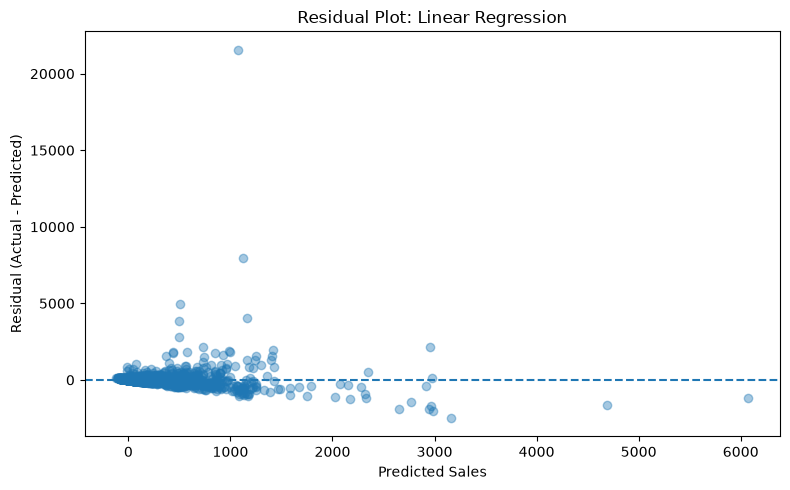

In [11]:
best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]

predictions = best_model.predict(X_test)
residuals = y_test.to_numpy() -predictions

print("Best model by RMSE:", best_name)

plt.figure(figsize=(8, 5))
plt.scatter(predictions, residuals, alpha=0.4)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Sales")
plt.ylabel("Residual (Actual - Predicted)")
plt.title(f"Residual Plot: {best_name}")
plt.tight_layout()
plt.show()

Tune your Decision Tree and Random Forest

In [13]:
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

train_groups = (
    model_df.iloc[train_idx]["Order ID"].to_numpy()
)

cv = GroupKFold(n_splits=5)

tree_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(random_state=42))
])

tree_params = {
    "model__max_depth": [5, 10, 20, None],
    "model__min_samples_leaf": [2, 5, 10]
}

tree_search = GridSearchCV(
    tree_pipeline,
    tree_params,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

tree_search.fit(
    X_train, y_train,
    groups=train_groups
)

print("Best tree parameters:", tree_search.best_params_)
print("Best CV RMSE:", -tree_search.best_score_)

Best tree parameters: {'model__max_depth': None, 'model__min_samples_leaf': 2}
Best CV RMSE: 455.17457195480677


Random Forest tuning

In [15]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

rf_params = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [10,20, None],
    "model__min_samples_leaf": [2, 5]
}

rf_search = GridSearchCV(
    rf_pipeline,
    rf_params,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=1
)

rf_search.fit(
    X_train, y_train,
    groups=train_groups
)

print("Best forest parameters:", rf_search.best_params_)
print("Best CV RMSE:", -rf_search.best_score_)

Best forest parameters: {'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__n_estimators': 100}
Best CV RMSE: 409.82380008688716


The negative sign is necessary because scikit-learn represents losses as negative scores when using its neg_root_mean_squared_error scorer. Negating best_score_ gives you the usual positive RMSE.

Compare the validation results

In [17]:
from sklearn.model_selection import cross_val_score

cv_comparison = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "CV_RMSE": -np.mean(
            cross_val_score(
                trained_models["Linear Regression"],
                X_train,
                y_train,
                cv=cv,
                groups=train_groups,
                scoring="neg_root_mean_squared_error",
                n_jobs=-1
            )
        )
    },
{
    "Model": "Tuned Decision Tree",
    "CV_RMSE": -tree_search.best_score_
},
{
    "Model": "Tuned Random Forest",
    "CV_RMSE": -rf_search.best_score_
}
]).sort_values("CV_RMSE")

print(cv_comparison.round(3).to_string(index=False))

              Model  CV_RMSE
  Linear Regression  401.878
Tuned Random Forest  409.824
Tuned Decision Tree  455.175


Evaluate the Selected Model.

In [21]:
best_tuned_model = (
    tree_search.best_estimator_
    if tree_search.best_score_ >= rf_search.best_score_
    else rf_search.best_estimator_
)

test_predictions = best_tuned_model.predict(X_test)

print("Test MAE:", mean_absolute_error(
    y_test, test_predictions
))
print("Test RMSE:", np.sqrt(mean_squared_error(
    y_test, test_predictions
)))
print("Test R\u00b2:", r2_score(
    y_test, test_predictions
))

Test MAE: 154.65386212140936
Test RMSE: 635.7485634684048
Test R²: 0.21945994328703944
